# Feature Engineering — Preparing Data for Machine Learning

**Week 7 · Tuesday · Preliminary review draft**

**Learning objectives**
- Explain why the same KNN model can behave differently after feature scaling.
- Distinguish feature selection, feature transformation, and feature creation.
- Fit preprocessing operations on training data only to avoid data leakage.
- Encode categorical variables and combine numerical/categorical transformations.
- Inspect residuals, compare train/test performance, and relate the number of neighbors to model complexity.
- Use a `Pipeline` to keep preprocessing and prediction together.

**Connection to Monday:** We already trained KNN on Iris and California Housing. Today we improve the *data preparation*, not the algorithm family.

## The feature engineering workflow

**Raw features → Train/test split → Learn preprocessing from TRAIN → Transform TRAIN and TEST → Fit model on TRAIN → Evaluate on TEST**

Three distinct operations:

- **Feature selection:** choose which existing columns to keep.
- **Feature transformation:** change the representation or scale of a column.
- **Feature creation:** derive new features from existing information.

**Key rule:** Anything that *learns* parameters from data (means, standard deviations, category vocabularies, imputing values, selection criteria) must learn them from **training data only**. Test data must remain unseen during fitting.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

RANDOM_STATE = 42

## Case study A — California Housing: Why scaling matters

KNN relies on distances. Features measured on large numerical scales may dominate those measured on smaller scales—even when both are useful.

We will compare **the same train/test split and the same `n_neighbors=10`** before and after scaling. This isolates the effect of preprocessing.

In [ ]:
housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame.copy()

display(housing_df.head())
print('Shape:', housing_df.shape)
print('Missing values:', housing_df.isna().sum().sum())
display(housing_df.describe().loc[['min', 'max']].T)

**Think (1 minute):** Compare the ranges of `Population`, `AveOccup`, `Latitude`, and `MedInc`. What might happen when KNN calculates Euclidean distances on these raw columns?

In [ ]:
X_housing = housing_df.drop(columns='MedHouseVal')
y_housing = housing_df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X_housing, y_housing, test_size=0.20, random_state=RANDOM_STATE
)

print('Train:', X_train.shape, 'Test:', X_test.shape)

### Baseline: KNN without scaling

We keep a **baseline** so that later improvements can be measured rather than assumed.

In [ ]:
knn_raw = KNeighborsRegressor(n_neighbors=10)
knn_raw.fit(X_train, y_train)

y_pred_train_raw = knn_raw.predict(X_train)
y_pred_test_raw = knn_raw.predict(X_test)

def regression_summary(model_name, y_train, y_pred_train, y_test, y_pred_test):
    """Return a compact train/test comparison (housing target is in $100,000 units)."""
    return pd.DataFrame({
        'Model': [model_name, model_name],
        'Split': ['Train', 'Test'],
        'MAE': [mean_absolute_error(y_train, y_pred_train),
                mean_absolute_error(y_test, y_pred_test)],
        'RMSE': [np.sqrt(mean_squared_error(y_train, y_pred_train)),
                 np.sqrt(mean_squared_error(y_test, y_pred_test))],
        'R²': [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
    })

results_raw = regression_summary(
    'Raw KNN', y_train, y_pred_train_raw, y_test, y_pred_test_raw
)
display(results_raw.round(3))

### Scaling with `MinMaxScaler`

For each feature, MinMax scaling maps the **training range** to approximately 0–1:

$$x_{scaled}=\frac{x-x_{min,train}}{x_{max,train}-x_{min,train}}$$

The scaler learns the training minima and maxima with `.fit(X_train)`. We apply **the same learned transformation** to both sets using `.transform(...)`.

A test value can lie outside 0–1: this is expected when it falls outside the training range.

**Why is this not a problem?** The transformation uses the training minimum and maximum as fixed reference points. A new observation can legitimately fall outside that historical range. Values outside `[0, 1]` are not errors, and we must **not refit** the scaler on test data. (The distance-based model may still find such extrapolating observations challenging.)

In [ ]:
minmax = MinMaxScaler()
minmax.fit(X_train)  # Learn parameters from TRAIN only.

X_train_scaled = pd.DataFrame(
    minmax.transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    minmax.transform(X_test), columns=X_test.columns, index=X_test.index
)

display(X_train_scaled.head())
print('Training feature ranges after scaling:')
display(X_train_scaled.agg(['min', 'max']).round(2))

**Check for understanding (2 minutes)**

1. Why is `minmax.fit(X_test)` incorrect, even though the target `y_test` is not used?
2. Why should we keep the original row indices when reconstructing DataFrames?

In [ ]:
knn_scaled = KNeighborsRegressor(n_neighbors=10)
knn_scaled.fit(X_train_scaled, y_train)

y_pred_train_scaled = knn_scaled.predict(X_train_scaled)
y_pred_test_scaled = knn_scaled.predict(X_test_scaled)

results_scaled = regression_summary(
    'MinMax KNN', y_train, y_pred_train_scaled, y_test, y_pred_test_scaled
)
display(pd.concat([results_raw, results_scaled], ignore_index=True).round(3))

**Discuss:** Did scaling improve the test performance? Did the train–test gap change? Do not assume that scaling *always* improves every model; its impact depends on the algorithm and data.

### Standardization: a different transformation

`StandardScaler` uses training statistics:

$$z=\frac{x-\mu_{train}}{\sigma_{train}}$$

It centers training features around 0 and gives them approximately unit standard deviation. Unlike MinMax scaling, it does **not** constrain values to a fixed interval.

Which scaler works better is an empirical question—not a universal rule.

In [ ]:
standard = StandardScaler()
X_train_standard = standard.fit_transform(X_train)
X_test_standard = standard.transform(X_test)

knn_standard = KNeighborsRegressor(n_neighbors=10)
knn_standard.fit(X_train_standard, y_train)

results_standard = regression_summary(
    'Standard KNN', y_train, knn_standard.predict(X_train_standard),
    y_test, knn_standard.predict(X_test_standard)
)
display(pd.concat([results_raw, results_scaled, results_standard], ignore_index=True).round(3))

## Feature selection — Choosing useful predictors

Selecting fewer features may reduce noise, complexity, and computation. But removing a feature because it has a low **individual linear correlation** with the target can discard useful nonlinear information.

We will first inspect relationships on **training data only**. This is an exploratory illustration, **not a formal feature-selection algorithm**.

In [ ]:
train_for_eda = X_train.copy()
train_for_eda['MedHouseVal'] = y_train

corr_to_target = (
    train_for_eda.corr(numeric_only=True)['MedHouseVal']
    .drop('MedHouseVal')
    .sort_values(key=abs, ascending=False)
)
display(corr_to_target.to_frame('Pearson correlation'))

plt.figure(figsize=(9, 5))
sns.heatmap(train_for_eda.corr(numeric_only=True), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Training data: Pearson correlations')
plt.tight_layout()
plt.show()

**Discussion (2 minutes):** `AveRooms` and `AveBedrms` are correlated with each other. Does that prove one of them is unnecessary for a distance-based model such as KNN? Why not?

**Note:** Pearson correlation describes *linear* relationships. Low individual correlation with the target does not rule out useful nonlinear relationships or interactions. VIF measures multicollinearity and is primarily useful when interpreting linear-model coefficients; it is not a KNN feature-selection rule. To determine whether dropping a feature improves generalization, we would compare alternatives using validation or cross-validation (Thursday), **not repeatedly inspect test scores**.

For now, the following smaller subset is illustrative, not an optimized choice.

### First introduction to `Pipeline` — Combining steps sequentially

A `Pipeline` runs named steps **in order**. We define it using a list of **tuples** `(name, step)`. Each name is chosen by us and must be unique within that pipeline.

```python
Pipeline([
    ('step_name_1', TransformerClass1()),
    ('step_name_2', TransformerClass2()),
    ('model_name', ModelClass()),
])
```

**Important:** Every *intermediate* step must be a **transformer** (it must implement `fit` and `transform`). The **last** step can be either another transformer (for a preprocessing-only pipeline) **or a predictive estimator** such as `KNeighborsRegressor` (for a complete machine-learning pipeline). The final predictive estimator needs `fit` but does not need `transform`.

In the next cell, `StandardScaler` transforms the selected columns and `KNeighborsRegressor` fits a model using those transformed features. Calling `.fit(...)` on the pipeline performs both operations in the correct order. Calling `.predict(...)` reuses the fitted scaler before predicting.

In [ ]:
# Illustrative subset, chosen for demonstration rather than optimized on the test set.
selected_features = ['MedInc', 'HouseAge', 'AveRooms', 'Latitude', 'Longitude']

knn_selected = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=10)),
])
knn_selected.fit(X_train[selected_features], y_train)

results_selected = regression_summary(
    'Selected features', y_train, knn_selected.predict(X_train[selected_features]),
    y_test, knn_selected.predict(X_test[selected_features])
)
display(pd.concat([results_standard, results_selected], ignore_index=True).round(3))

## Error analysis — Residuals

A **residual** is the observed target minus the prediction:

$$e_i=y_i-\hat{y}_i$$

- Positive residual → the model **underpredicted**.
- Negative residual → the model **overpredicted**.

A residual plot can reveal patterns that a single MAE or R² value hides. The California Housing target is capped, which may affect the pattern.

In [ ]:
residuals_test = y_test - y_pred_test_scaled

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_test_scaled, residuals_test, s=10, alpha=0.25)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Predicted value ($100,000s)', ylabel='Residual (actual − predicted)',
            title='Residuals vs predictions — Test')
sns.histplot(residuals_test, bins=35, ax=axes[1])
axes[1].set(xlabel='Residual ($100,000s)', title='Residual distribution — Test')
plt.tight_layout()
plt.show()

**Check for understanding (2 minutes):** If the residuals form a visible curve instead of a random-looking cloud around zero, what might that suggest about the model?

## Model complexity — What happens when we change `k`?

Small `k` makes KNN more flexible; large `k` produces smoother predictions. We will **illustrate** train/test behavior, not select the final `k` using test scores.

**Important:** In a real modeling workflow, hyperparameters should be selected using a validation set or cross-validation. We will study that on Thursday.

In [ ]:
k_values = [1, 2, 3, 5, 10, 20, 40, 80]
k_results = []
for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    k_results.append({
        'k': k,
        'Train MAE': mean_absolute_error(y_train, model.predict(X_train_scaled)),
        'Test MAE': mean_absolute_error(y_test, model.predict(X_test_scaled)),
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df.round(3))
ax = k_results_df.plot(x='k', y=['Train MAE', 'Test MAE'], marker='o', figsize=(8, 4))
# Major ticks every 10 units; unlabeled minor ticks every 2 units.
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(2))
ax.tick_params(axis='x', which='major', length=7)
ax.tick_params(axis='x', which='minor', length=3)
ax.set_xlim(0, max(k_values) + 1)
ax.set(xlabel='Number of neighbors (k)', ylabel='MAE ($100,000s)',
       title='Illustrating complexity (not tuning on the test set)')
plt.tight_layout()
plt.show()

**Discuss:** Why can `k=1` give an extremely small training error? Does the lowest training error guarantee the best predictions on unseen observations?

## Case study B — Different feature types in one dataset

Imagine a small **bicycle rental service**. Each booking has numerical variables (`TripDistanceKm`, `RiderAge`), a nominal category (`BikeType`), and an **ordinal** category (`MembershipTier`: Bronze < Silver < Gold).

- **Nominal:** categories have no inherent order → `OneHotEncoder`.
- **Ordinal:** categories have a meaningful order → `OrdinalEncoder` with an explicit order.
- **Numerical:** may need scaling for a distance-based model → `MinMaxScaler` or `StandardScaler`.

This is a **toy teaching dataset**, not a real-world performance benchmark. Its purpose is to make preprocessing transparent.

In [ ]:
bookings = pd.DataFrame({
    'TripDistanceKm': [2.1, 7.5, 4.2, 12.0, 1.8, 9.1, 3.3, 5.6, 15.2, 6.4, 8.3, 2.8],
    'RiderAge': [22, 44, 31, 28, 53, 39, 26, 47, 34, 29, 41, 36],
    'BikeType': ['City', 'Electric', 'Road', 'City', 'Electric', 'Road',
                 'City', 'Road', 'Electric', 'City', 'Electric', 'Road'],
    'MembershipTier': ['Bronze', 'Gold', 'Silver', 'Bronze', 'Gold', 'Silver',
                       'Silver', 'Gold', 'Bronze', 'Silver', 'Gold', 'Bronze'],
    'LateReturn': [0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1],
})
display(bookings.head())
print('Class counts:')
print(bookings['LateReturn'].value_counts())

### Fit an encoder on training data only

We split before learning preprocessing parameters. `OneHotEncoder(handle_unknown='ignore')` represents an unseen nominal category as all zeros within its feature group. `OrdinalEncoder` needs an **explicit category order**, because alphabetical order does not necessarily match meaning.

**Important:** Ordinal encoding preserves order, but its numeric codes also impose equal spacing between consecutive tiers. That is a modeling assumption, not a property guaranteed by the original categories.

**How are the codes assigned?** By default, `OrdinalEncoder()` determines the categories from the training data and assigns consecutive integer codes starting at 0. The order is **not necessarily the order in which rows appear**, and should not be assumed to represent business meaning. For an ordered feature, pass `categories=[['Bronze', 'Silver', 'Gold']]` to explicitly define **Bronze → 0, Silver → 1, Gold → 2**.

The `categories` argument controls the **order**, not arbitrary numeric values. To assign custom scores (e.g. 0, 5, 20), use a deliberate mapping such as `Series.map()` or a custom transformer. Such values also encode assumptions about the *distance* between levels.

[OrdinalEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html).

In [ ]:
X_bookings = bookings.drop(columns='LateReturn')
y_bookings = bookings['LateReturn']
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bookings, y_bookings, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_bookings
)

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_b[['BikeType']])
encoded_train = pd.DataFrame(
    encoder.transform(X_train_b[['BikeType']]),
    columns=encoder.get_feature_names_out(['BikeType']),
    index=X_train_b.index,
)
display(encoded_train.head())

**Check for understanding (2 minutes):** Why is `BikeType = 3` not a meaningful way to represent a nominal category? Why should `MembershipTier` be treated differently? What would happen if a test booking used a previously unseen bike type?

## Processing different feature types — Three branches, one workflow

`ColumnTransformer` applies different preprocessing to different feature groups, then **recombines the transformed columns**. `Pipeline` connects that preprocessing to the model so that the same learned transformations are used during training and prediction.

For our distance-based KNN example, we choose:

- **Numerical:** `SimpleImputer` → `MinMaxScaler`.
- **Nominal:** `OneHotEncoder` (one indicator per category).
- **Ordinal:** `OrdinalEncoder` with an explicit order → `MinMaxScaler`.

On the training data, these branches produce columns in approximately the same **[0, 1] range**. This is a useful starting point, **not a guarantee of equal importance**: a nominal feature represented by several one-hot columns, an ordinal feature with assumed equal steps, and differences in distributions can all affect Euclidean distances.

**Why not simply scale everything again?** A second global scaler is *not required* for KNN to work. It may also change the relative weight of binary indicators and the meaning of the chosen encoding. We should select transformations deliberately and evaluate their effect using validation, rather than automatically stacking scalers.

The diagram below shows how our bicycle rental features are split, processed independently, and recombined.

### Reusing `Pipeline` for preprocessing only

Earlier, we used a pipeline that **ended in a model**. Now we need three preprocessing branches, each of which will end in a **transformer**. We will define them separately before combining them.

The same tuple syntax applies:

```python
Pipeline([
    ('step_name_1', TransformerClass1()),
    ('step_name_2', TransformerClass2()),
])
```

A preprocessing pipeline has `.fit(...)` and `.transform(...)`, so it can be used as a transformer inside `ColumnTransformer`.

### Nominal categorical features — A separate pipeline

`BikeType` has **no intrinsic order**, so we use `OneHotEncoder`. A pipeline can contain just **one step**; using the same structure for all three branches makes their later combination easier to read.

In [ ]:
# Branch 2: nominal categories — create indicator columns.
nominal_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

print(nominal_pipeline)

### Ordinal categorical features — A third pipeline

`MembershipTier` **does** have an order. We specify it explicitly in `OrdinalEncoder` and then scale the resulting codes. The codes preserve the order, but treating adjacent levels as equally spaced is a modeling assumption.

In [ ]:
# Branch 3: ordered categories — encode in the chosen order, then scale.
ordinal_pipeline = Pipeline([
    ('encoder', OrdinalEncoder(
        categories=[['Bronze', 'Silver', 'Gold']],
        handle_unknown='use_encoded_value',
        unknown_value=-1,
    )),
    ('scaler', MinMaxScaler()),
])

print(ordinal_pipeline)

In [ ]:
numeric_features = ['TripDistanceKm', 'RiderAge']
nominal_features = ['BikeType']
ordinal_features = ['MembershipTier']

# Branch 1: numerical variables — impute missing values, then scale.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
])

print(numeric_pipeline)

### Combining the three branches with `ColumnTransformer`

Now that the **three preprocessing pipelines already exist**, `ColumnTransformer` lets us apply them to **different subsets of columns** and concatenate their outputs.

Unlike `Pipeline`, which receives **tuples** `(name, step)`, `ColumnTransformer` receives **triples** `(name, transformer, columns)`:

```python
ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('nominal', nominal_pipeline, nominal_features),
    ('ordinal', ordinal_pipeline, ordinal_features),
])
```

Here, each `transformer` is one of our previously defined pipelines. More generally, the second element **can be a single transformer or a complete preprocessing pipeline**: a pipeline ending in a transformer behaves as a transformer itself. A pipeline ending in a predictive model is **not** suitable as a preprocessing branch because `ColumnTransformer` needs to call `.transform(...)`.

The final step is to put this `ColumnTransformer` into a **new pipeline** with the KNN classifier. The diagram below shows the three independent branches and their recombination.

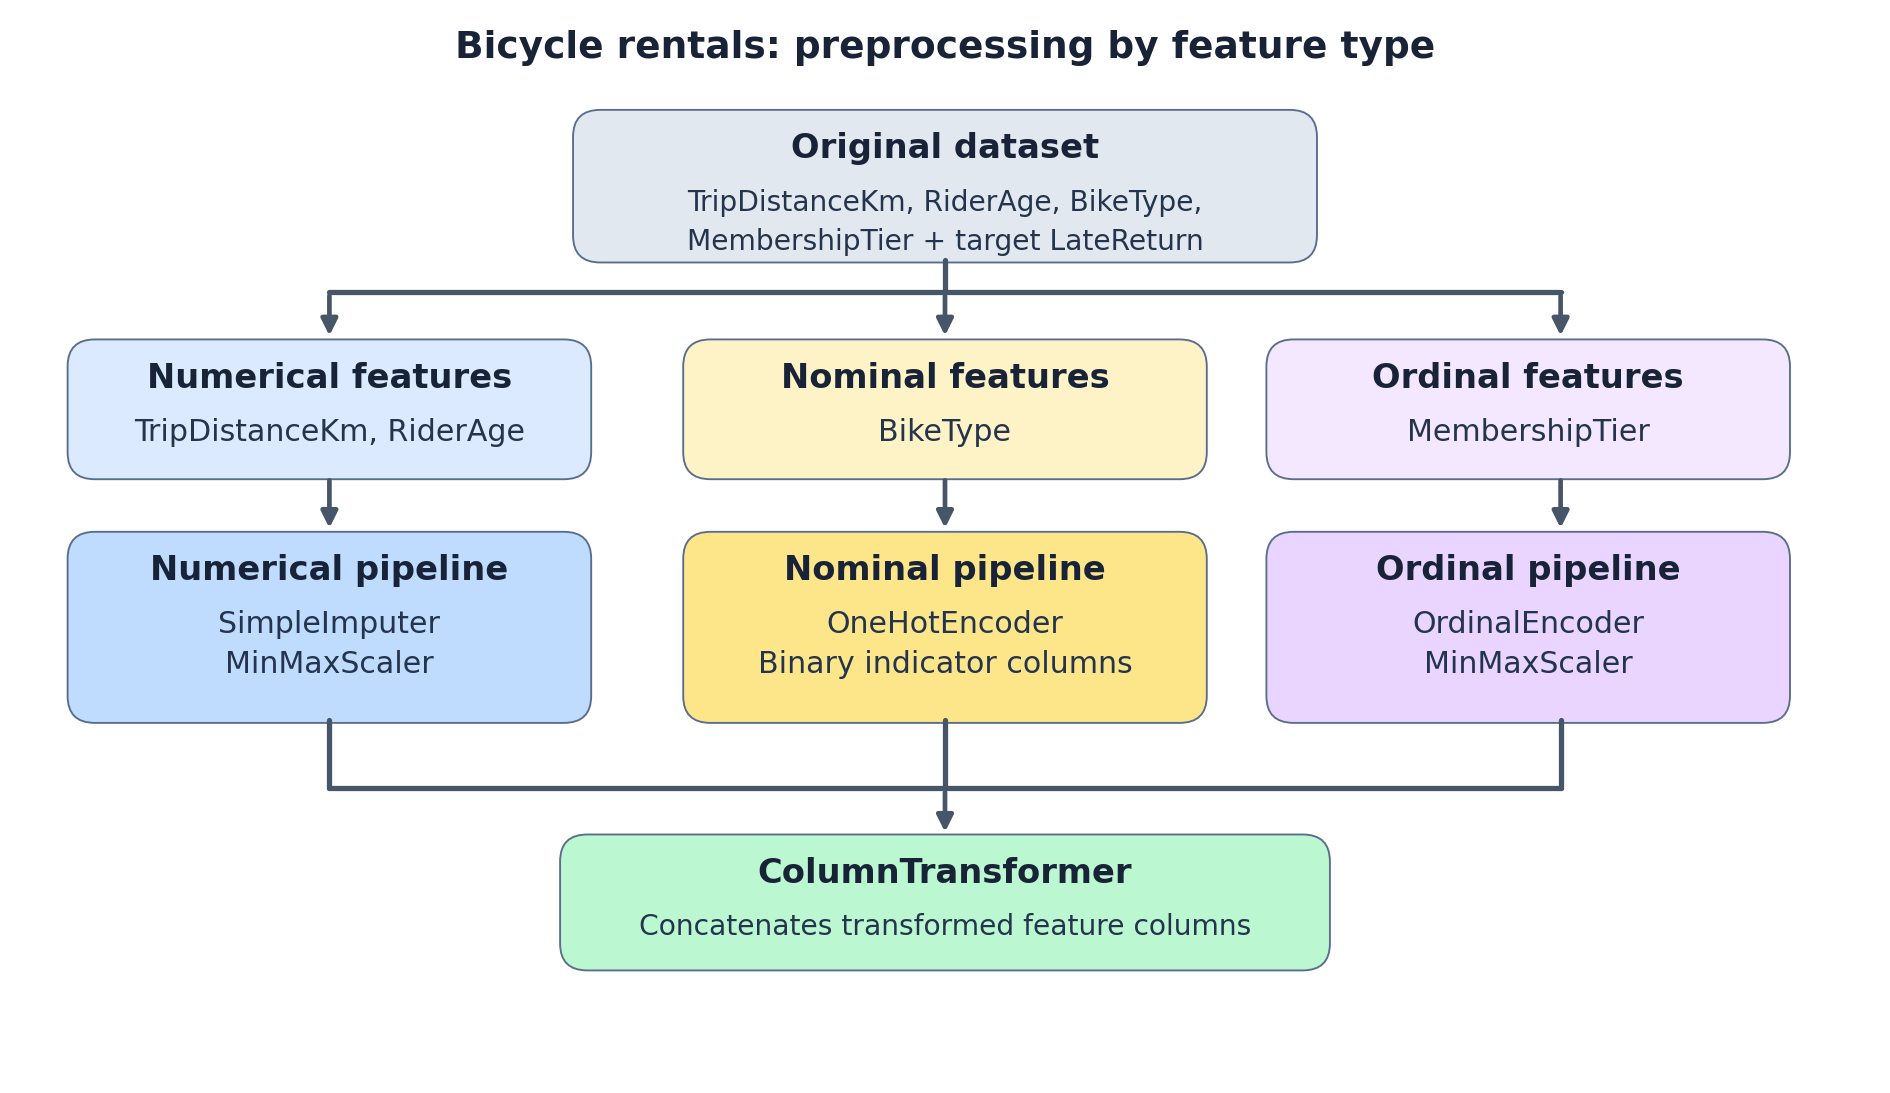

In [ ]:
# Visual overview of the three preprocessing branches.
# The diagram is saved in this cell's output, so it is visible without running the cell.
# To recreate it programmatically, use Matplotlib boxes and arrows as shown in class.


In [ ]:
# Combine the three previously defined preprocessing branches.
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('nominal', nominal_pipeline, nominal_features),
    ('ordinal', ordinal_pipeline, ordinal_features),
])

# Complete workflow: preprocessing transformer followed by a predictive model.
booking_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=3)),
])

booking_pipeline.fit(X_train_b, y_train_b)
print('Training accuracy:', round(booking_pipeline.score(X_train_b, y_train_b), 3))
print('Test accuracy:', round(booking_pipeline.score(X_test_b, y_test_b), 3))
print('Small illustrative dataset: do not interpret these scores as reliable estimates.')

**Why is the pipeline safer?** `.fit(X_train_b, y_train_b)` learns preprocessing parameters from training data; `.predict(X_test_b)` reuses them without refitting.

**Ordinal encoding and distances:** `OrdinalEncoder` maps Bronze, Silver, and Gold to 0, 1, and 2. The additional `MinMaxScaler` maps them to 0, 0.5, and 1 (based on the observed training range), preserving their order. **This still assumes equally spaced levels**, which may not reflect their real-world meaning. Also, a previously unseen ordinal category is encoded as `-1` and may produce a value below zero after scaling; that is not an error, but handling unknown categories deserves care in real projects.

## Saving the complete workflow

We can save a **fitted pipeline**, not just its estimator, so future predictions reuse the same preprocessing.

`joblib` is a **third-party Python package**, commonly installed as a dependency of scikit-learn; it is **not** part of Python's standard library. If it is missing, install it in your **active environment** using one of these alternatives: `uv add joblib`, `python -m pip install joblib`, or `conda install joblib` (for a conda environment). You only need **one** of these commands. Only load serialized objects from trusted sources: loading them can execute arbitrary Python code.

The code below is optional and does not write files unless you uncomment it.

In [ ]:
# Optional: save and reload your fitted pipeline.
# import joblib
# joblib.dump(booking_pipeline, 'bicycle_rental_knn_pipeline.joblib')
# restored_pipeline = joblib.load('bicycle_rental_knn_pipeline.joblib')  # Trusted files only!
# restored_pipeline.predict(X_test_b.head(2))

## Independent practice — Apply today's ideas

Using **California Housing** and the existing split:

1. Compare raw KNN, MinMax scaling, and StandardScaler using **test MAE and R²**.
2. Explain which features are likely to dominate unscaled Euclidean distances.
3. Interpret at least one pattern in the residual plot.
4. Explain why comparing many `k` values on the test set is *not* a valid final tuning strategy.

**Connection to today's lab:** For Spaceship Titanic, you will need to handle missing values, derive a useful feature from `Cabin`, encode categories, split the data, and train KNN. Avoid fitting preprocessing on the entire dataset before splitting.

In [ ]:
# TODO: Write a short comparison of the preprocessing strategies.
# Which model would you investigate further, and why?

## Self-learning — Beyond today's lesson

These topics are optional extensions; follow the links for the official scikit-learn documentation:

- **Feature creation:** ratios, domain-driven combinations, and interactions; see [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html).
- **Skewed distributions:** [`PowerTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html) (including Yeo–Johnson) and [`FunctionTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html) for custom log transforms.
- **Target transformations:** [`TransformedTargetRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html).
- **Target encoding:** [`TargetEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html), including cross-fitting to reduce leakage.
- **Systematic feature selection:** [`SelectKBest`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html) (univariate scoring) and [`RFE`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html) (recursive feature elimination).

We will introduce formal cross-validation and hyperparameter tuning on Thursday. Do not repeatedly optimize feature choices using the test set.

## Key takeaways

- KNN depends on distances, so feature scales matter.
- Always split **before fitting** scalers, imputers, encoders, or data-driven selectors.
- Train/test metrics and residuals reveal different aspects of performance.
- Varying `k` illustrates underfitting and overfitting; **do not tune on the test set**.
- `ColumnTransformer` can route numerical, nominal, and ordinal variables to different transformations; `Pipeline` helps keep preprocessing reproducible and leakage-resistant.
- The best preprocessing choice must be evaluated carefully, not assumed.